# F — Fully kinetic (particle-in-cell) plasma models of comets

**Tutorial F1 · Cometary Plasma Modeling series**

The third model family in Goetz et al. (2022, *Space Sci. Rev.* 218:65, Table 5) treats **all** plasma species, electrons included, as computational particles. These are **fully kinetic** particle-in-cell (PIC) codes. They are the only way to capture physics that depends on electron dynamics:

* the **ambipolar electric field**: hot, light electrons outrun the heavy ions and the resulting charge separation pulls the ions outward (Goetz et al. 2022, Sect. 2.3.3);
* **electron trapping** and the distinct cold / warm / hot electron populations seen by Rosetta (Deca et al. 2017; Sishtla et al. 2019; Divin et al. 2020);
* electron-scale waves and the electron terms of the generalised Ohm's law (Deca et al. 2019).

| Code / work | Method | Comet application |
|---|---|---|
| **iPIC3D** (Markidis et al. 2010) | 3-D, semi-implicit (implicit-moment) electromagnetic PIC | Deca et al. (2017, 2019): solar wind interacting with a weakly outgassing 67P-like comet; Sishtla et al. (2019) electron trapping; Divin et al. (2020) electron acceleration |
| Explicit electrostatic / electromagnetic PIC (textbook: Birdsall & Langdon 1991) | Leapfrog particles, Poisson or Maxwell solver | The method built here |

**The price.** A fully kinetic code must resolve the Debye length $\lambda_D$ and the electron plasma period $\omega_{pe}^{-1}$, or step over them stably with an implicit scheme. Those scales are 10³–10⁵ times smaller than the ion scales a hybrid code resolves. Two standard tricks keep runs affordable: a **reduced ion-to-electron mass ratio**, and in electromagnetic codes a **reduced speed of light**. This notebook makes the mass-ratio trick visible. We run the same problem at several mass ratios and extrapolate to the real one.

> **Learning goals.** (i) Build a 1-D electrostatic PIC code: deposit, field solve, gather, push. (ii) Validate it on the plasma oscillation. (iii) Use it to grow an **ambipolar potential** around an ionising cometary source, and test the result against the Boltzmann relation and the Bohm criterion.

## 1. Equations and normalisation

Each species $s$ (electrons, $q=-e$, and cometary ions, $q=+e$, $m_i=\mu\,m_e$) is sampled by macro-particles:
$$ \frac{dx_p}{dt}=v_p,\qquad \frac{dv_p}{dt}=\frac{q_s}{m_s}E(x_p), $$
with the electrostatic field from Gauss's law (1-D Poisson):
$$ \frac{d^2\phi}{dx^2} = -\frac{e(n_i-n_e)}{\varepsilon_0},\qquad E=-\frac{d\phi}{dx}. $$

**Units**: reference density $n_0$, electron temperature $T_e$, so lengths are in $\lambda_D=\sqrt{\varepsilon_0 k_BT_e/n_0e^2}$, times in $\omega_{pe}^{-1}$, speeds in $v_{te}=\lambda_D\omega_{pe}$, and potentials in $k_BT_e/e$. For cometary photoelectrons, $k_BT_e\approx 10$ eV (Goetz et al. 2022, Table 2), so $\phi=1$ is ≈ 10 V. Ions are cold at birth. In 1-D the field solve is a tridiagonal system, solved exactly here.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
import time
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

L, Ng = 60.0, 120                     # domain [lambda_D], number of cells
dx = L/Ng; xg = np.arange(Ng+1)*dx    # grid nodes; phi = 0 at both ends (grounded, absorbing walls)
dt = 0.1                              # [1/omega_pe]  (omega_pe*dt << 2 for leapfrog stability)
w = 0.002                             # macro-particle weight [n0 * lambda_D]

# tridiagonal Laplacian for interior nodes
ab = np.zeros((3, Ng-1)); ab[0, 1:] = 1; ab[1] = -2; ab[2, :-1] = 1

def deposit(x):
    """Cloud-in-cell density on the nodes."""
    g = x/dx; i = np.floor(g).astype(int); f = g - i
    n = (np.bincount(i, 1-f, Ng+1) + np.bincount(i+1, f, Ng+2)[:Ng+1])*w/dx
    n[[0, -1]] *= 2                   # boundary nodes own only half a cell
    return n

def solve_field(ni, ne):
    phi = np.zeros(Ng+1)
    phi[1:-1] = solve_banded((1, 1), ab, -(ni-ne)[1:-1]*dx*dx)
    return phi, -np.gradient(phi, dx)

def gather(E, x):
    g = x/dx; i = np.floor(g).astype(int); f = g - i
    return E[i]*(1-f) + E[np.minimum(i+1, Ng)]*f

## 2. Validation: the plasma oscillation
Displace a cold, uniform electron population sinusoidally against a fixed ion background, with reflecting walls for this test only. The electrons should oscillate at $\omega=\omega_{pe}=1$. This tests the deposit, the field solve and the push together, and is the standard first test for any PIC code.

measured oscillation frequency = 0.995 omega_pe  (theory: 1.000; FFT resolution ±0.013)


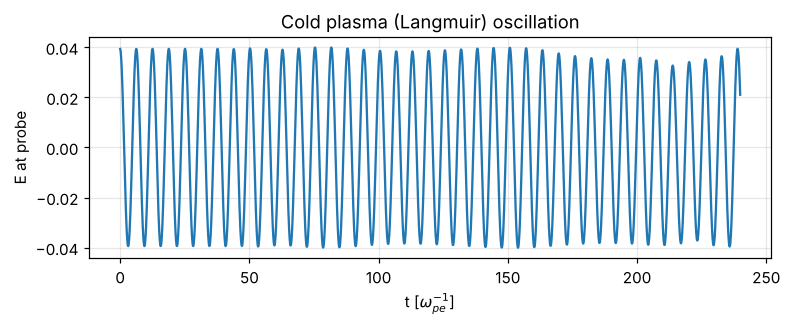

In [2]:
N = int(L/w)
xe = (np.arange(N)+0.5)*L/N
mode, A = 3, 0.05
xe = xe + A*np.sin(mode*np.pi*xe/L)
ve = np.zeros(N); ni = np.ones(Ng+1)                         # immobile neutralising ions
probe = []
for it in range(2400):
    phi, E = solve_field(ni, deposit(xe))
    ve -= gather(E, xe)*dt; xe += ve*dt
    out = (xe < 0) | (xe > L); ve[out] *= -1; xe = np.where(xe < 0, -xe, np.where(xe > L, 2*L - xe, xe))  # reflect
    probe.append(E[Ng//(2*mode)])
probe = np.array(probe)
freq = np.fft.rfftfreq(len(probe), dt)*2*np.pi; spec = np.abs(np.fft.rfft(probe - probe.mean()))
w_meas = freq[np.argmax(spec)]
print(f'measured oscillation frequency = {w_meas:.3f} omega_pe  (theory: 1.000; FFT resolution ±{freq[1]/2:.3f})')
plt.figure(figsize=(8, 2.6)); plt.plot(np.arange(len(probe))*dt, probe)
plt.xlabel('t [$\\omega_{pe}^{-1}$]'); plt.ylabel('E at probe'); plt.title('Cold plasma (Langmuir) oscillation'); plt.show()

## 3. A cometary ionisation source and its ambipolar field

**Set-up.** This mimics the inner coma along one direction. Electron–ion pairs are created at a rate $\propto 1/((x-x_0)^2+a^2)$, the 1-D analogue of the Haser source. Electrons are born **warm** ($T_e=1$, ≈ 10 eV photoelectrons) and ions are born nearly **at rest**. Both species leave through the domain edges. The walls are grounded ($\phi=0$) and stand in for the distant plasma.

**One modelling choice to note.** In a strictly collisionless 1-D run, electrons trapped in the potential well can never escape, because they cannot change their energy. They then cool by evaporation: only the fast ones leave. At a real comet, continuous photoelectron production, electron–neutral collisions and 3-D motion keep re-energising them. We represent this with a simple **Krook (BGK) thermostat**: each electron is re-drawn from a $T_e=1$ Maxwellian at rate $\nu_c=0.2\,\omega_{pe}$. This kind of reduced collision operator is common in PIC studies. Exercise 2 asks you to turn it off.

In [3]:
x0, a, Te = L/2, 3.0, 1.0

def run_coma(mu, nuc=0.2, seed=0, n_tres=4.0, avg_tres=1.5):
    """Grow and average the steady state of an ionising slab for ion/electron mass ratio mu."""
    rng = np.random.default_rng(seed)
    cs = np.sqrt(Te/mu)                   # ion acoustic speed
    S = cs                                # pair production rate [n0 v_te]; scales the density to ~1
    Tres = (L/2)/cs                       # ion escape time
    nsteps, navg = int(n_tres*Tres/dt), int(avg_tres*Tres/dt)
    xe = ve = xi = vi = np.empty(0); carry = 0.0
    acc = {'phi': 0, 'ne': 0, 'ni': 0}; nb = 60; Hv = np.zeros(nb); Hc = np.zeros(nb); Te_loc = []
    for it in range(nsteps):
        carry += S*dt/w; k = int(carry); carry -= k                              # ionisation
        s = x0 + a*np.tan(rng.uniform(-np.arctan(x0/a), np.arctan(x0/a), k))
        xe = np.r_[xe, s]; ve = np.r_[ve, np.sqrt(Te)*rng.standard_normal(k)]
        xi = np.r_[xi, s]; vi = np.r_[vi, 0.1*cs*rng.standard_normal(k)]
        ne, ni = deposit(xe), deposit(xi); phi, E = solve_field(ni, ne)          # field
        ve -= gather(E, xe)*dt; vi += gather(E, xi)*dt/mu                        # push
        th = rng.uniform(size=ve.size) < nuc*dt; ve[th] = np.sqrt(Te)*rng.standard_normal(th.sum())  # thermostat
        xe += ve*dt; xi += vi*dt
        m = (xe > 0) & (xe < L); xe, ve = xe[m], ve[m]                           # absorbing walls
        m = (xi > 0) & (xi < L); xi, vi = xi[m], vi[m]
        if it >= nsteps - navg:                                                  # time average
            for key, val in (('phi', phi), ('ne', ne), ('ni', ni)): acc[key] = acc[key] + val/navg
            Hv += np.histogram(xi, nb, (0, L), weights=vi)[0]; Hc += np.histogram(xi, nb, (0, L))[0]
            core = np.abs(xe - x0) < 10; Te_loc.append(ve[core].var())
    acc['ui'] = Hv/np.maximum(Hc, 1); acc['xb'] = np.linspace(0, L, nb+1)[:-1] + L/nb/2
    acc['Te_core'] = np.mean(Te_loc); acc['cs'] = cs
    acc['final'] = (xe, ve, xi, vi)
    return acc

results = {}
t0 = time.time()
for mu in (16, 64, 256):
    results[mu] = run_coma(mu)
    r = results[mu]
    print(f'mu = {mu:4d}: peak potential = {r["phi"].max():.2f} kTe/e, core Te = {r["Te_core"]:.2f}, '
          f'peak density = {r["ne"].max():.2f} n0   ({time.time()-t0:.0f} s)')

mu =   16: peak potential = 1.12 kTe/e, core Te = 0.92, peak density = 1.41 n0   (10 s)


mu =   64: peak potential = 1.76 kTe/e, core Te = 0.94, peak density = 1.17 n0   (27 s)


mu =  256: peak potential = 2.46 kTe/e, core Te = 0.96, peak density = 1.05 n0   (57 s)


## 4. Results for $\mu = 256$

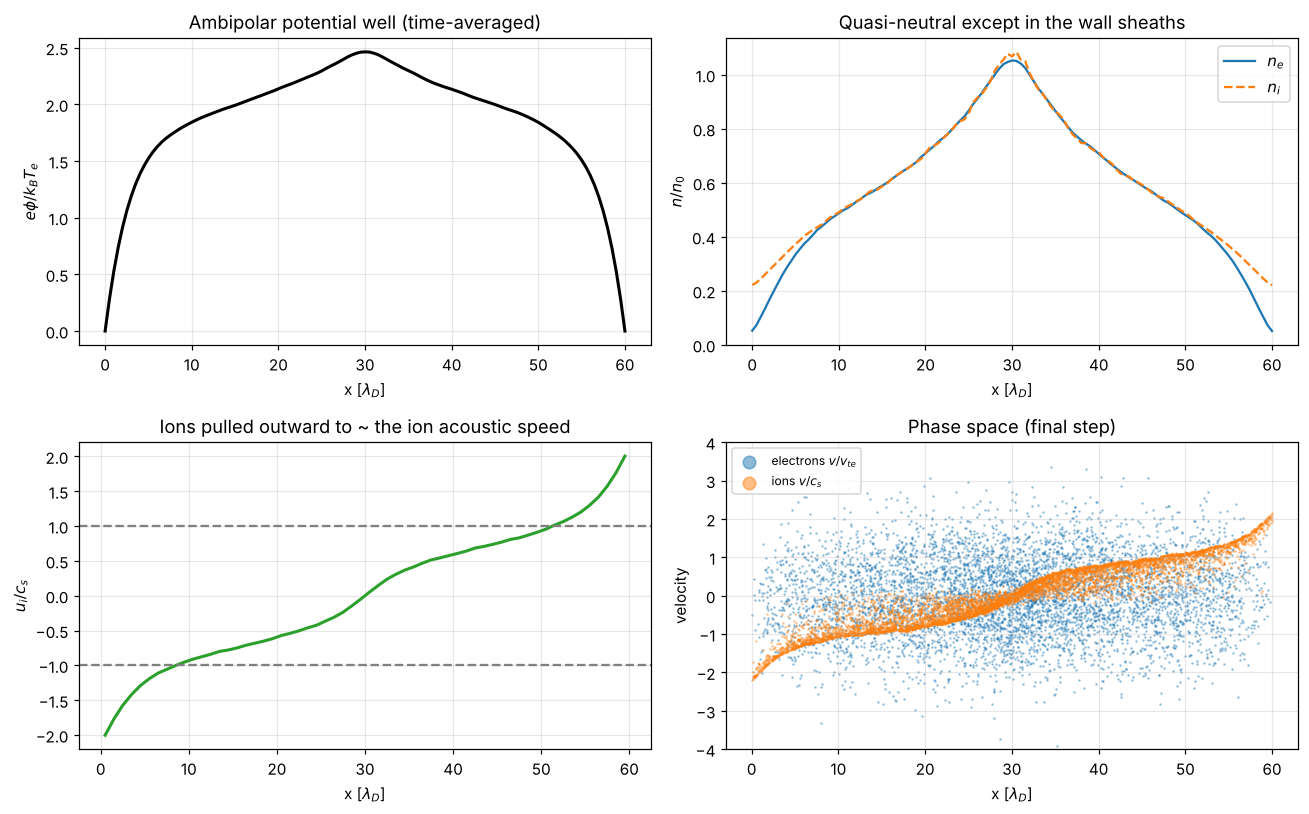

In [4]:
r = results[256]; xe, ve, xi, vi = r['final']
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
ax[0,0].plot(xg, r['phi'], 'k', lw=2); ax[0,0].set(ylabel='$e\\phi/k_BT_e$', title='Ambipolar potential well (time-averaged)')
ax[0,1].plot(xg, r['ne'], label='$n_e$'); ax[0,1].plot(xg, r['ni'], '--', label='$n_i$')
ax[0,1].set(ylabel='$n/n_0$', title='Quasi-neutral except in the wall sheaths'); ax[0,1].legend()
ax[1,0].plot(r['xb'], r['ui']/r['cs'], 'C2', lw=2); ax[1,0].axhline(1, color='gray', ls='--'); ax[1,0].axhline(-1, color='gray', ls='--')
ax[1,0].set(ylabel='$u_i/c_s$', title='Ions pulled outward to ~ the ion acoustic speed', xlabel='x [$\\lambda_D$]')
sub_e = slice(None, None, max(1, len(xe)//6000)); sub_i = slice(None, None, max(1, len(xi)//6000))
ax[1,1].scatter(xe[sub_e], ve[sub_e], s=0.3, alpha=0.5, label='electrons $v/v_{te}$')
ax[1,1].scatter(xi[sub_i], vi[sub_i]/r['cs'], s=0.3, alpha=0.5, label='ions $v/c_s$')
ax[1,1].set(xlabel='x [$\\lambda_D$]', ylabel='velocity', title='Phase space (final step)', ylim=(-4, 4)); ax[1,1].legend(markerscale=15, loc='upper left', fontsize=8)
for a_ in ax[0]: a_.set_xlabel('x [$\\lambda_D$]')
plt.tight_layout(); plt.show()

### 4a. Physics checks
1. **Boltzmann electrons.** Where electrons are confined by the potential and carry little net flux, they should satisfy $n_e\propto e^{e\phi/k_BT_e}$. Plotting $\phi$ against $\ln n_e$ in the quasi-neutral region should then give a slope equal to $T_e$ (measured independently from the electron velocities). Our thermostat also acts as a **friction** on the outward electron flux, which must equal the ion flux $\propto c_s \propto \mu^{-1/2}$. So we expect the deviation $1-\text{slope}/T_e$ to shrink like $\mu^{-1/2}$ and the Boltzmann relation to be recovered as $\mu$ approaches its real value. This relation underlies the analytic ambipolar-field models of Vigren et al. (2015) and Madanian et al. (2016). Deca et al. (2019) found near-isothermal cometary electrons in their 3-D PIC runs.
2. **Bohm criterion.** Ions must reach the ion acoustic speed $c_s=\sqrt{k_BT_e/m_i}$ by the edge of the quasi-neutral region, where the sheath begins (panel above). Rosetta's radially expanding cometary ions were similarly found at ion-acoustic-like speeds (≈10 km/s for 10 eV electrons; Goetz et al. 2022, Sect. 2.3.3).

mu =   16: Boltzmann slope = 0.38, core Te = 0.92,  (1 - slope/Te)*sqrt(mu) = 2.35
mu =   64: Boltzmann slope = 0.59, core Te = 0.94,  (1 - slope/Te)*sqrt(mu) = 2.96
mu =  256: Boltzmann slope = 0.79, core Te = 0.96,  (1 - slope/Te)*sqrt(mu) = 2.79


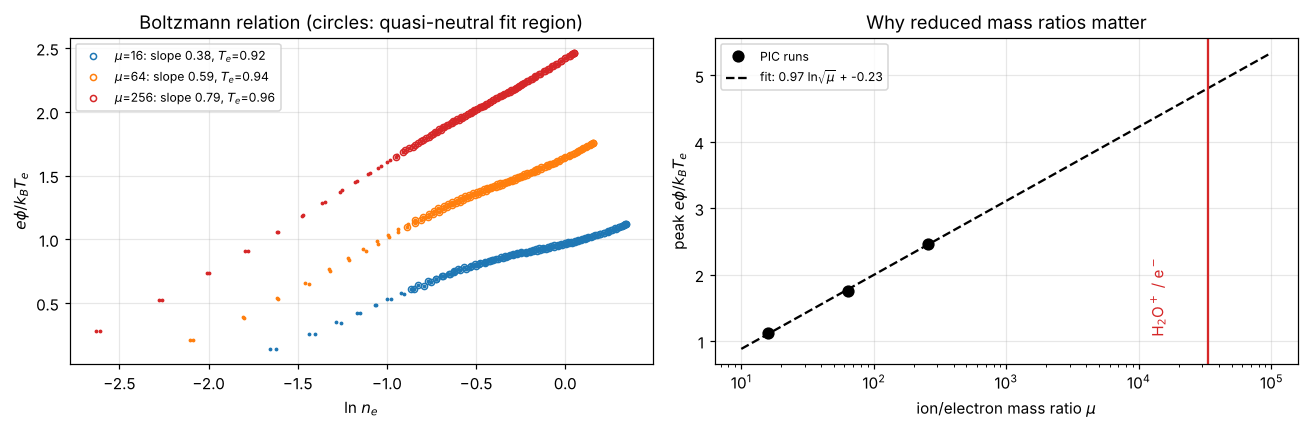

Slope of potential vs ln(sqrt(mu)): 0.97  (flux-balance estimate: ~1)
Extrapolated peak potential for real H2O+ mass: 4.8 kTe/e  ->  ~48 V for 10-eV electrons


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for mu, c in zip(results, ['C0', 'C1', 'C3']):
    r = results[mu]; qn = (np.abs(r['ni']-r['ne']) < 0.05*r['ne']) & (r['ne'] > 0.2)   # quasi-neutral nodes
    slope = np.polyfit(np.log(r['ne'][qn]), r['phi'][qn], 1)[0]
    print(f'mu = {mu:4d}: Boltzmann slope = {slope:.2f}, core Te = {r["Te_core"]:.2f},  (1 - slope/Te)*sqrt(mu) = {(1-slope/r["Te_core"])*np.sqrt(mu):.2f}')
    ax[0].plot(np.log(r['ne'][1:-1]), r['phi'][1:-1], '.', color=c, ms=3)
    ax[0].plot(np.log(r['ne'][qn]), r['phi'][qn], 'o', color=c, ms=4, mfc='none', label=f'$\\mu$={mu}: slope {slope:.2f}, $T_e$={r["Te_core"]:.2f}')
ax[0].set(xlabel='ln $n_e$', ylabel='$e\\phi/k_BT_e$', title='Boltzmann relation (circles: quasi-neutral fit region)'); ax[0].legend(fontsize=8)

mus = np.array(list(results)); dphi = np.array([results[m]['phi'].max() for m in mus])
fit = np.polyfit(np.log(np.sqrt(mus)), dphi, 1)
mu_real = 18*1836.15
mm = np.geomspace(10, 1e5, 100)
ax[1].semilogx(mus, dphi, 'ko', ms=7, label='PIC runs')
ax[1].semilogx(mm, np.polyval(fit, np.log(np.sqrt(mm))), 'k--', label=f'fit: {fit[0]:.2f} ln$\\sqrt{{\\mu}}$ + {fit[1]:.2f}')
ax[1].axvline(mu_real, color='C3'); ax[1].text(mu_real*0.5, dphi.min(), 'H$_2$O$^+$ / e$^-$', color='C3', rotation=90, ha='right')
ax[1].set(xlabel='ion/electron mass ratio $\\mu$', ylabel='peak $e\\phi/k_BT_e$', title='Why reduced mass ratios matter'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

phi_real = np.polyval(fit, np.log(np.sqrt(mu_real)))
print(f'Slope of potential vs ln(sqrt(mu)): {fit[0]:.2f}  (flux-balance estimate: ~1)')
print(f'Extrapolated peak potential for real H2O+ mass: {phi_real:.1f} kTe/e  ->  ~{10*phi_real:.0f} V for 10-eV electrons')

**Interpretation.**
* **Boltzmann check.** The product $(1-\text{slope}/T_e)\sqrt{\mu}$ stays roughly constant (≈ 2.4–3.0) across a 16× range of $\mu$. That is the expected $\mu^{-1/2}$ friction scaling, so the departure from Boltzmann is a known, shrinking effect of the thermostat, not a code error. At the real mass ratio it would be ≈ 2 %.
* The potential well deepens by roughly $k_BT_e/e$ for every factor $e$ in $\sqrt{\mu}$. That follows from flux balance: the escaping electron flux, $\propto n\,v_{te}\,e^{-e\Delta\phi/k_BT_e}$, must equal the ion flux, $\propto n\,c_s$, so $e\Delta\phi/k_BT_e \approx \ln(v_{te}/c_s) = \ln\sqrt{\mu}$ plus a constant.
* A simulation at $\mu=16$–$256$ therefore **underestimates** the ambipolar potential of a real water-ion coma. Extrapolating gives a few $k_BT_e/e$, i.e. a few tens of volts. That is the order needed to accelerate solar-wind electrons to the 50–60 eV energies discussed by Deca et al. (2017) and Divin et al. (2020), and to drive the cometary ions outward at ~10 km/s. Treat the extrapolation as order-of-magnitude: it is 1-D and planar, has grounded walls and uses a thermostat.
* The 3-D codes add the solar wind and magnetic field. Electrons are then trapped by the combined ambipolar $E$ and the piled-up $B$ (Sishtla et al. 2019), and the electron-pressure term dominates Ohm's law near the nucleus (Deca et al. 2019). A hybrid code with an isothermal electron fluid (tutorial E) captures part of this through its $-\nabla p_e/en$ term. A fully kinetic code is needed for the electron **distributions** themselves.

## 5. From this notebook to iPIC3D-type codes

| This tutorial | Production fully kinetic codes |
|---|---|
| 1-D, electrostatic, explicit leapfrog | 3-D electromagnetic; semi-implicit (implicit-moment) time stepping lets $\Delta t \gg \omega_{pe}^{-1}$ (iPIC3D) |
| μ = 16–256, extrapolated | Reduced mass ratio (typically ~10²) **and** reduced speed of light; results checked for sensitivity |
| Grounded absorbing walls | Open boundaries with solar-wind inflow; neutral coma and ionisation as volume sources |
| Krook thermostat | Self-consistent photo-/solar-wind electrons; some studies add electron–neutral collisions via Monte-Carlo modules |
| ~2×10⁴ particles | 10⁹–10¹¹ particles on supercomputers |

### Exercises
1. Re-run the plasma-oscillation test with warm electrons ($v_{th}=1$) and a higher mode number. Compare with the Bohm–Gross relation $\omega^2=\omega_{pe}^2(1+3k^2\lambda_D^2)$.
2. Set `nuc=0` (no thermostat). Explain the cold, trapped electron population that appears. How does it relate to the cold electrons Rosetta saw inside the electron exobase (Goetz et al. 2022, Sect. 2.3.5)?
3. Give the ions a birth speed of 1 km/s (in units of $c_s$) and see whether the potential changes.
4. Add a second, hotter electron population ($T_h = 5T_e$, 10 % of the density) to mimic the "hot" population. Which population sets the potential?
5. *(Advanced)* Turn the code into a 1-D3V electromagnetic PIC with a uniform $B$. Gyrating electrons can no longer escape freely across $B$: a first step toward the trapping of Sishtla et al. (2019).

## References
* Birdsall, C. K., & Langdon, A. B. (1991). *Plasma Physics via Computer Simulation*. IOP Publishing.
* Deca, J., et al. (2017). Electron and ion dynamics of the solar wind interaction with a weakly outgassing comet. *Phys. Rev. Lett.*, 118, 205101.
* Deca, J., et al. (2019). Building a weakly outgassing comet from a generalized Ohm's law. *Phys. Rev. Lett.*, 123, 055101.
* Goetz, C., et al. (2022). The plasma environment of comet 67P/Churyumov-Gerasimenko. *Space Sci. Rev.*, 218, 65.
* Markidis, S., Lapenta, G., & Rizwan-uddin (2010). Multi-scale simulations of plasma with iPIC3D. *Math. Comput. Simul.*, 80, 1509–1519.
* Sishtla, C. P., et al. (2019). Electron trapping in the coma of a weakly outgassing comet. *Phys. Plasmas*, 26, 102904.
* Divin et al. (2020), Madanian et al. (2016), Vigren et al. (2015): see the reference list of Goetz et al. (2022) for full citations.